# Placement 2, part 4: coronal slices through the hippocampus


Radiologists rate Alzheimer atrophy on **coronal** slices through the hippocampus (the MTA scale of Scheltens et al., 1992), where the hippocampus, the temporal horn and the choroid fissure are seen side by side. Several 2D studies also report that coronal slices of the medial temporal lobe work best. This notebook therefore builds coronal slices from the original OASIS-1 volumes and repeats the main experiments on them.



## 1. Setup
The same setup as notebook 3: the authors' code at the same commit, Dassl on the Python path, and the same helper functions.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/placement2'
OUTPUTS = f'{PROJECT}/outputs'     # one folder per run, with Dassl's log.txt
RESULTS = f'{PROJECT}/results'     # tables and figures for the report
DATA = '/content/data'
BIOMEDCOOP = '/content/BiomedCoOp'
for d in (OUTPUTS, RESULTS, f'{RESULTS}/figures', DATA):
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
%%bash
cd /content
if [ ! -d BiomedCoOp ]; then git clone -q https://github.com/HealthX-Lab/BiomedCoOp.git; fi
cd BiomedCoOp
git checkout -q 23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d
echo "BiomedCoOp at commit $(git rev-parse --short HEAD)"

pip install -q yacs gdown ftfy regex tabulate tensorboard timm wilds==1.2.2 open_clip_torch==2.23.0 transformers==4.35.2

sed -i 's/super().__init__(optimizer, last_epoch, verbose)/super().__init__(optimizer, last_epoch)/'     Dassl.pytorch/dassl/optim/lr_scheduler.py
grep -c "super().__init__(optimizer, last_epoch)" Dassl.pytorch/dassl/optim/lr_scheduler.py

cd Dassl.pytorch && python -c "import dassl; print('dassl', dassl.__version__)"
python -c "import torch; print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))"

BiomedCoOp at commit 23710b0
1
dassl 0.5.0
torch 2.14.1+cu130 | GPU: Tesla T4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.35.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import glob, re, subprocess, sys
import numpy as np
import pandas as pd

SHOTS = [1, 2, 4, 8, 16]   # labelled images per class, as in the paper


DASSL = f'{BIOMEDCOOP}/Dassl.pytorch'
ENV = {**os.environ, 'PYTHONPATH': f"{DASSL}:{BIOMEDCOOP}:{os.environ.get('PYTHONPATH', '')}"}

COMMON_OPTS = ['TEST.COMPUTE_CMAT', 'True', 'TEST.PER_CLASS_RESULT', 'True',
               'DATALOADER.NUM_WORKERS', '2']


def run_finished(out_dir):
    """A run counts as done once its log has a test accuracy in it."""
    for log in glob.glob(f'{out_dir}/log.txt*'):
        if '* accuracy:' in open(log, errors='ignore').read():
            return True
    return False


def run(trainer, dataset_cfg, trainer_cfg, out_dir, shots=None, seed=None,
        opts=(), eval_only=False, script=f'{BIOMEDCOOP}/train.py'):
    """Runs one training/test job with the authors' train.py (or my wrapper).

    Only the result lines are printed here, to keep the notebook readable.
    Dassl writes the full output to log.txt in out_dir."""
    if run_finished(out_dir):
        print(f'already done: {out_dir.replace(OUTPUTS + "/", "")}')
        return
    cmd = [sys.executable, script, '--root', DATA, '--trainer', trainer,
           '--dataset-config-file', dataset_cfg, '--config-file', trainer_cfg,
           '--output-dir', out_dir]
    if seed is not None:
        cmd += ['--seed', str(seed)]
    if eval_only:
        cmd += ['--eval-only']
    cmd += list(opts) + COMMON_OPTS
    if shots is not None:
        cmd += ['DATASET.NUM_SHOTS', str(shots)]

    print(f'\n{out_dir.replace(OUTPUTS + "/", "")}')
    proc = subprocess.Popen(cmd, cwd=BIOMEDCOOP, env=ENV, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    tail = []
    for line in proc.stdout:
        tail = (tail + [line])[-40:]
        if line.startswith(('* accuracy', '* macro_f1')):
            print('   ', line.strip())
    if proc.wait() != 0:
        # Stop here instead of carrying on with a broken setup.
        print(''.join(tail))
        raise RuntimeError(f'run failed: {out_dir}')


def read_result(run_dir):
    """Reads the final test metrics back from a run's log."""
    text = ''.join(open(f, errors='ignore').read() for f in sorted(glob.glob(f'{run_dir}/log.txt*')))
    acc = re.findall(r'\* accuracy: ([\d.]+)%', text)
    if not acc:
        return None
    row = {'accuracy': float(acc[-1]),
           'macro_f1': float(re.findall(r'\* macro_f1: ([\d.]+)%', text)[-1])}
    last = text[text.rfind('* macro_f1'):]
    for name, acc_c in re.findall(r'\* class: \d+ \((.+?)\).*?acc: ([\d.]+)%', last):
        row[f'acc_{name}'] = float(acc_c)
    return row


def collect(dataset):
    """All finished runs of one dataset -> (one row per run, mean/std per method and K)."""
    rows = []
    for log in glob.glob(f'{OUTPUTS}/{dataset}/**/log.txt', recursive=True):
        run_dir = os.path.dirname(log)
        res = read_result(run_dir)
        if res is None:
            continue
        parts = os.path.relpath(run_dir, f'{OUTPUTS}/{dataset}').split('/')
        shots = next((int(p[6:]) for p in parts if p.startswith('shots_')), 0)
        seed = next((int(p[4:]) for p in parts if p.startswith('seed')), 0)
        rows.append({'method': parts[0], 'shots': shots, 'seed': seed, **res})
    runs = pd.DataFrame(rows).sort_values(['method', 'shots', 'seed']).reset_index(drop=True)
    metrics = [c for c in runs.columns if c in ('accuracy', 'macro_f1') or c.startswith('acc_')]
    summary = runs.groupby(['method', 'shots'])[metrics].agg(['mean', 'std']).round(2)
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    summary.insert(0, 'n_seeds', runs.groupby(['method', 'shots']).size())
    runs.to_csv(f'{RESULTS}/{dataset}_runs.csv', index=False)
    summary.reset_index().to_csv(f'{RESULTS}/{dataset}_summary.csv', index=False)
    return runs, summary.reset_index()

## 2. Coronal slices from the OASIS-1 volumes


In [ ]:
# The same 200 participants, labels and train/val/test parts as notebook 3.
import glob, re, json, shutil, subprocess, zipfile
sel_csv = pd.read_csv(f'{RESULTS}/OASIS1_selected_slices.csv')
people = sel_csv.drop_duplicates('subject')[['subject', 'part', 'label', 'age', 'cdr']].set_index('subject')
people['y'] = (people.label > 0).astype(int)
print(people.groupby(['part', 'y']).size().unstack().rename(columns={0: 'no dementia', 1: 'dementia'}))

y      no dementia  dementia
part                        
test            24        16
train           71        49
val             24        16


In [ ]:
!pip install -q nibabel
import nibabel as nib
from PIL import Image

COR_DIR = f'{DATA}/coronal_all'                     # every coronal slice, for the analysis
COR_ZIP = f'{PROJECT}/oasis1_coronal_slices.zip'    # kept on Drive after the first run
VOL_DIR = '/content/oasis_volumes'
Y_RANGE = range(40, 171)                            # coronal positions, front-to-back
FLIP_VERTICAL = False                               # set True if the preview below is upside down
os.makedirs(COR_DIR, exist_ok=True)


def volume_path(subject):
    found = glob.glob(f'{VOL_DIR}/**/{subject}_MR1_*_t88_masked_gfc.img', recursive=True)
    return found[0] if found else None


def coronal(vol, y, scale):
    img = np.rot90(vol[:, y, :])
    if FLIP_VERTICAL:
        img = np.flipud(img)
    return Image.fromarray(np.clip(img / scale * 255, 0, 255).astype(np.uint8))


if os.path.exists(COR_ZIP):
    zipfile.ZipFile(COR_ZIP).extractall(COR_DIR)
    print('coronal slices restored from Drive')
else:
    os.makedirs(VOL_DIR, exist_ok=True)
    for disc in range(1, 13):
        if all(volume_path(s) for s in people.index):
            break
        url = f'https://download.nrg.wustl.edu/data/oasis_cross-sectional_disc{disc}.tar.gz'
        tgz = f'/content/disc{disc}.tar.gz'
        print(f'disc {disc}: downloading...', end=' ', flush=True)
        subprocess.run(['wget', '-q', '-c', url, '-O', tgz], check=True)
        subprocess.run(['tar', '-xzf', tgz, '-C', VOL_DIR, '--wildcards',
                        '*_t88_masked_gfc.img', '*_t88_masked_gfc.hdr'], check=True)
        os.remove(tgz)
        print(f'{sum(bool(volume_path(s)) for s in people.index)} of {len(people)} participants found so far')
    missing = [s for s in people.index if not volume_path(s)]
    assert not missing, f'no volume found for {missing}'

    for s in people.index:
        img = nib.as_closest_canonical(nib.load(volume_path(s)))
        vol = np.squeeze(np.asarray(img.dataobj, dtype=np.float32))
        scale = np.percentile(vol[vol > 0], 99.5)
        for y in Y_RANGE:
            coronal(vol, y, scale).save(f'{COR_DIR}/{s}_{y:03d}.jpg', quality=95)
    with zipfile.ZipFile(COR_ZIP, 'w') as z:
        for f in glob.glob(f'{COR_DIR}/*.jpg'):
            z.write(f, os.path.basename(f))
    shutil.rmtree(VOL_DIR, ignore_errors=True)
    print('coronal slices saved and zipped to Drive')
print(len(glob.glob(f'{COR_DIR}/*.jpg')), 'coronal slices')

coronal slices restored from Drive
26200 coronal slices


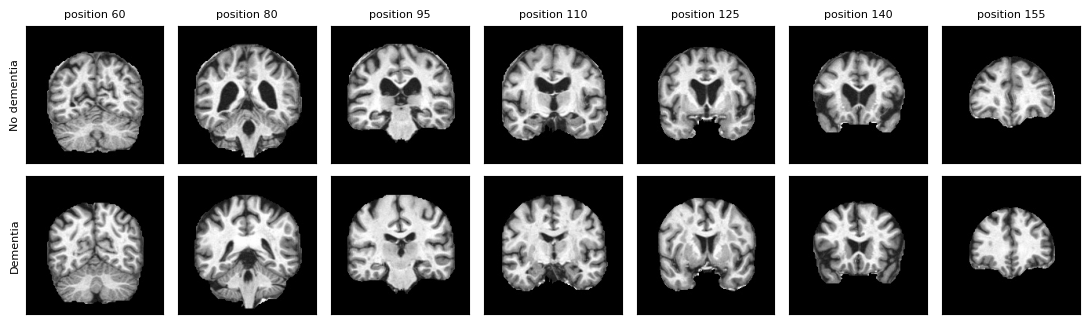

In [ ]:
import matplotlib.pyplot as plt
show = [people[(people.y == 0) & (people.part == 'train')].index[0],
        people[(people.y == 1) & (people.part == 'train')].index[0]]
ys = [60, 80, 95, 110, 125, 140, 155]
fig, axes = plt.subplots(2, len(ys), figsize=(11, 3.4))
for r, s in enumerate(show):
    for c, y in enumerate(ys):
        axes[r, c].imshow(plt.imread(f'{COR_DIR}/{s}_{y:03d}.jpg'), cmap='gray')
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(f'position {y}', fontsize=8)
    axes[r, 0].set_ylabel(['No dementia', 'Dementia'][r], fontsize=8)
fig.tight_layout()
fig.savefig(f'{RESULTS}/figures/oasis1_coronal_examples.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# The list of all coronal slices, in the same format as in notebook 3.
rows = [{'file': f, 'subject': '_'.join(os.path.basename(f).split('_')[:2]),
         'slice': int(os.path.basename(f).split('_')[2][:3])} for f in sorted(glob.glob(f'{COR_DIR}/*.jpg'))]
allcor = pd.DataFrame(rows)
allcor = allcor[allcor.subject.isin(people.index)].sort_values(['subject', 'slice']).reset_index(drop=True)
allcor['part'] = allcor.subject.map(people.part)
allcor['y'] = allcor.subject.map(people.y)
allcor['age'] = allcor.subject.map(people.age)
os.makedirs('/content/alz_ext', exist_ok=True)
allcor[['file', 'subject', 'slice', 'part', 'y', 'age']].to_csv('/content/alz_ext/all_slices_coronal.csv', index=False)
MID_FIRST = 100        # a middle window, used as the 'no choice' reference in section 5
print(f'{allcor.subject.nunique()} participants, {len(allcor)} slices, positions {allcor.slice.min()}-{allcor.slice.max()}')

200 participants, 26200 slices, positions 40-170


## 3. Class descriptions
The same four sets as in notebook 3 (original, visible-anatomy, detailed without negation, medial temporal lobe), with "axial" replaced by "coronal", since the images are now coronal.

In [ ]:
ORIGINAL = {
    "no dementia": [
        "An axial brain MRI showing full, rounded hippocampi with narrow temporal horns, indicating no dementia.",
        "A brain MRI slice with tightly packed cortical gyri and thin sulci across both hemispheres, consistent with no dementia.",
        "An MRI of the brain with small, slit-like lateral ventricles and no enlargement of the temporal horns, suggesting no dementia.",
        "An axial MRI showing a thick, well-preserved cortical ribbon in the temporal and parietal lobes, indicating no dementia.",
        "A brain MRI with a narrow Sylvian fissure and no widening of the space around the medial temporal lobe, consistent with no dementia.",
        "An MRI slice of the brain where the medial temporal lobe fills its space with little surrounding cerebrospinal fluid, suggesting no dementia.",
        "An axial brain MRI with symmetrical hemispheres, normal-sized ventricles and no visible tissue loss, indicating no dementia.",
        "A brain MRI showing only mild, age-appropriate sulcal widening with preserved hippocampal volume, consistent with no dementia.",
        "An MRI of the brain in which the gray matter is evenly thick and the white matter appears full and uniform, suggesting no dementia.",
        "An axial MRI slice showing a compact third ventricle and closely opposed frontal and temporal gyri, indicating no dementia.",
        "A brain MRI with clearly defined hippocampal heads and no dark fluid gap between the hippocampus and the brainstem, consistent with no dementia.",
        "An MRI of the brain showing narrow cortical sulci over the parietal lobes and no posterior atrophy, suggesting no dementia.",
        "An axial brain MRI in which the brain tissue fills most of the skull with only a thin rim of surrounding fluid, indicating no dementia.",
        "A brain MRI slice with small frontal horns of the lateral ventricles and a normal caudate outline, consistent with no dementia.",
        "An MRI showing intact entorhinal and parahippocampal cortex with no thinning of the medial temporal lobe, suggesting no dementia.",
        "An axial brain MRI with sharply defined gray-white matter boundaries and no areas of cortical thinning, indicating no dementia.",
        "A brain MRI with temporal lobes of normal size and a narrow temporal horn on both sides, consistent with no dementia.",
        "An MRI of the brain showing a normal width of the interhemispheric fissure and full frontal lobes, suggesting no dementia.",
        "An axial MRI slice in which the ventricles are small relative to the surrounding brain tissue, indicating no dementia.",
        "A brain MRI showing a normal precuneus and posterior cingulate region with tight sulci, consistent with no dementia.",
        "An MRI of the brain with no hippocampal shrinkage and a choroidal fissure that is barely visible, suggesting no dementia.",
        "An axial brain MRI showing healthy brain volume for age, with no ventricular or sulcal enlargement, indicating no dementia.",
        "A brain MRI slice with evenly spaced gyri and no deepening of the sulci in the temporal or parietal cortex, consistent with no dementia.",
        "An MRI of the brain with an intact insular cortex and a closed Sylvian fissure, suggesting no dementia.",
        "An axial MRI showing symmetrical medial temporal lobes of normal height on both sides, indicating no dementia.",
        "A brain MRI with a smooth, normal ventricular outline and no rounding or ballooning of the ventricles, consistent with no dementia.",
        "An MRI slice of the brain in which the cortex appears full in all lobes, with no regional pattern of tissue loss, suggesting no dementia.",
        "An axial brain MRI showing a small amount of cerebrospinal fluid over the convexities and in the basal cisterns, indicating no dementia.",
        "A brain MRI with well-preserved white matter volume and a normally thick corpus callosum, consistent with no dementia.",
        "An MRI of the brain showing hippocampi of normal shape with a clear internal structure, suggesting no dementia.",
        "An axial MRI slice with narrow sulci and plump gyri in the frontal, temporal and parietal lobes, indicating no dementia.",
        "A brain MRI showing no widening of the perihippocampal fissures and no enlargement of the temporal horns, consistent with no dementia.",
        "An MRI of the brain with a normal brain-to-fluid ratio and no global loss of brain volume, suggesting no dementia.",
        "An axial brain MRI in which the lateral ventricles are narrow and do not extend into enlarged temporal horns, indicating no dementia.",
        "A brain MRI slice showing a normal thickness of the parietal cortex with no posterior predominant atrophy, consistent with no dementia.",
        "An MRI showing no visible shrinkage of the medial temporal lobe and preserved amygdala volume, suggesting no dementia.",
        "An axial MRI of the brain with compact ventricles, thin sulci and a normal Sylvian fissure, indicating no dementia.",
        "A brain MRI showing the typical brain shape of a healthy older adult with only minimal sulcal prominence, consistent with no dementia.",
        "An MRI slice of the brain with intact cortical folding and no flattening or thinning of the gyri, suggesting no dementia.",
        "An axial brain MRI with symmetrical, normal-sized ventricles and no asymmetric temporal atrophy, indicating no dementia.",
        "A brain MRI showing normal hippocampal width and a well-defined collateral sulcus, consistent with no dementia.",
        "An MRI of the brain in which the space between the brain surface and the skull is narrow, suggesting no dementia.",
        "An axial MRI slice showing a normal-sized third ventricle and closely spaced thalami, indicating no dementia.",
        "A brain MRI with uniform gray matter signal and no regions of reduced cortical volume, consistent with no dementia.",
        "An MRI of the brain showing preserved temporal lobe volume with no widening of the temporal sulci, suggesting no dementia.",
        "An axial brain MRI in which the frontal horns are small and the caudate heads keep their normal convex shape, indicating no dementia.",
        "A brain MRI slice with no medial temporal lobe atrophy on visual rating and normal ventricular size, consistent with no dementia.",
        "An MRI showing full cerebral hemispheres with a thin layer of fluid in the sulci, suggesting no dementia.",
        "An axial brain MRI with normal volume in the hippocampus, entorhinal cortex and temporal neocortex, indicating no dementia.",
        "A brain MRI showing a healthy, age-appropriate brain with no pattern of atrophy typical of Alzheimer's disease, consistent with no dementia."
    ],
    "very mild dementia": [
        "An axial brain MRI showing slight narrowing of the hippocampi with early widening of the temporal horns, indicating very mild dementia.",
        "A brain MRI slice with subtle thinning of the medial temporal lobe and a slightly more visible choroidal fissure, consistent with very mild dementia.",
        "An MRI of the brain showing mildly widened sulci in the temporal lobes while the rest of the cortex looks largely preserved, suggesting very mild dementia.",
        "An axial MRI with a small increase in cerebrospinal fluid around the hippocampi compared with a healthy brain, indicating very mild dementia.",
        "A brain MRI showing early, subtle volume loss in the entorhinal cortex with otherwise near-normal brain structure, consistent with very mild dementia.",
        "An MRI slice of the brain with slightly enlarged lateral ventricles and minimal sulcal widening, suggesting very mild dementia.",
        "An axial brain MRI showing a faint widening of the Sylvian fissures and the temporal sulci, indicating very mild dementia.",
        "A brain MRI with mild hippocampal volume loss that is only just visible on an axial slice, consistent with very mild dementia.",
        "An MRI of the brain showing early thinning of the parietal cortex with slightly deeper sulci over the precuneus, suggesting very mild dementia.",
        "An axial MRI slice in which the temporal horns are slightly larger than expected for age, indicating very mild dementia.",
        "A brain MRI showing borderline medial temporal lobe atrophy with a small dark gap next to the hippocampus, consistent with very mild dementia.",
        "An MRI of the brain with mild, diffuse sulcal prominence slightly beyond what is typical for age, suggesting very mild dementia.",
        "An axial brain MRI showing early asymmetric shrinkage of one hippocampus with the other still near normal, indicating very mild dementia.",
        "A brain MRI slice with slightly rounded frontal horns and a marginally widened third ventricle, consistent with very mild dementia.",
        "An MRI showing subtle loss of temporal lobe volume, with gyri that look slightly thinner than in a healthy brain, suggesting very mild dementia.",
        "An axial brain MRI with a thin but visible rim of extra fluid along the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI showing a mild increase in the size of the lateral ventricles while the cortex remains mostly intact, consistent with very mild dementia.",
        "An MRI of the brain in which the hippocampal head appears slightly flattened, suggesting very mild dementia.",
        "An axial MRI slice showing early widening of the posterior cingulate and parietal sulci, indicating very mild dementia.",
        "A brain MRI with slight enlargement of the perihippocampal fissures and the temporal horn, consistent with very mild dementia.",
        "An MRI of the brain showing a small reduction in overall brain volume relative to the skull, suggesting very mild dementia.",
        "An axial brain MRI with faint cortical thinning in the temporal and parietal lobes and preserved frontal lobes, indicating very mild dementia.",
        "A brain MRI slice in which the medial temporal lobe looks slightly smaller than normal on visual rating, consistent with very mild dementia.",
        "An MRI showing mild opening of the Sylvian fissure and slight thinning of the insular cortex, suggesting very mild dementia.",
        "An axial MRI of the brain showing early ventricular enlargement with the temporal horns starting to open up, indicating very mild dementia.",
        "A brain MRI with gyri that are slightly narrower and sulci that are slightly wider than expected for age, consistent with very mild dementia.",
        "An MRI of the brain showing subtle volume loss in the parahippocampal gyrus with an otherwise normal-looking slice, suggesting very mild dementia.",
        "An axial brain MRI with a mild increase of fluid in the basal cisterns around the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI slice showing early hippocampal atrophy that is easy to miss without comparison to a healthy scan, consistent with very mild dementia.",
        "An MRI showing slightly deepened temporal sulci and a mildly prominent collateral sulcus, suggesting very mild dementia.",
        "An axial brain MRI in which the lateral ventricles are just above normal size for an older adult, indicating very mild dementia.",
        "A brain MRI showing a subtle pattern of temporoparietal volume loss with preserved occipital lobes, consistent with very mild dementia.",
        "An MRI of the brain with slight thinning of the cortical ribbon in the medial temporal region, suggesting very mild dementia.",
        "An axial MRI slice showing a narrow but visible fluid space separating the hippocampus from surrounding structures, indicating very mild dementia.",
        "A brain MRI with mild widening of the interhemispheric fissure and slight frontal sulcal prominence, consistent with very mild dementia.",
        "An MRI of the brain showing early shrinkage of the amygdala and hippocampus with mild temporal horn dilation, suggesting very mild dementia.",
        "An axial brain MRI with slightly more cerebrospinal fluid over the convexities than in a healthy brain of the same age, indicating very mild dementia.",
        "A brain MRI slice showing minimal but definite hippocampal volume loss on both sides, consistent with very mild dementia.",
        "An MRI showing a slightly enlarged choroidal fissure and early thinning of the medial temporal cortex, suggesting very mild dementia.",
        "An axial MRI of the brain with mild ventricular rounding and slight widening of the cortical sulci, indicating very mild dementia.",
        "A brain MRI showing early posterior cortical thinning around the precuneus with near-normal hippocampi, consistent with very mild dementia.",
        "An MRI of the brain in which the temporal lobes look marginally smaller than the frontal lobes would suggest, suggesting very mild dementia.",
        "An axial brain MRI showing faint widening of the sulci between the temporal gyri, indicating very mild dementia.",
        "A brain MRI slice with a small increase in temporal horn width and slight hippocampal flattening, consistent with very mild dementia.",
        "An MRI showing early, mild global atrophy with slightly enlarged ventricles and sulci, suggesting very mild dementia.",
        "An axial MRI of the brain with subtle entorhinal and hippocampal volume loss and a preserved cortex elsewhere, indicating very mild dementia.",
        "A brain MRI showing mild medial temporal lobe atrophy, rated as just above normal on a visual scale, consistent with very mild dementia.",
        "An MRI of the brain with slightly widened parietal and temporal sulci and a mildly open Sylvian fissure, suggesting very mild dementia.",
        "An axial brain MRI in which the brain still looks largely normal apart from early hippocampal shrinkage, indicating very mild dementia.",
        "A brain MRI showing the earliest visible stage of the atrophy pattern of Alzheimer's disease, centred on the medial temporal lobe, consistent with very mild dementia."
    ],
    "mild dementia": [
        "An axial brain MRI showing clear shrinkage of both hippocampi with widened temporal horns, indicating mild dementia.",
        "A brain MRI slice with obvious medial temporal lobe atrophy and an enlarged choroidal fissure, consistent with mild dementia.",
        "An MRI of the brain showing moderately enlarged lateral ventricles and widened cortical sulci, suggesting mild dementia.",
        "An axial MRI with a clear gap of cerebrospinal fluid around the shrunken hippocampi, indicating mild dementia.",
        "A brain MRI showing visible thinning of the temporal and parietal cortex with deepened sulci, consistent with mild dementia.",
        "An MRI slice of the brain with a widened Sylvian fissure and visible loss of temporal lobe volume, suggesting mild dementia.",
        "An axial brain MRI showing enlarged temporal horns that are clearly visible next to atrophic hippocampi, indicating mild dementia.",
        "A brain MRI with definite hippocampal atrophy and moderate widening of the sulci over both hemispheres, consistent with mild dementia.",
        "An MRI of the brain showing clear parietal atrophy with widened sulci around the precuneus and posterior cingulate, suggesting mild dementia.",
        "An axial MRI slice in which the lateral ventricles are noticeably larger than normal for age, indicating mild dementia.",
        "A brain MRI showing medial temporal lobe atrophy that is easy to see on an axial slice, with thin parahippocampal gyri, consistent with mild dementia.",
        "An MRI of the brain with moderate global atrophy, enlarged ventricles and more fluid between the gyri, suggesting mild dementia.",
        "An axial brain MRI showing shrunken temporal lobes with widened temporal sulci on both sides, indicating mild dementia.",
        "A brain MRI slice with enlarged frontal horns and a widened third ventricle, consistent with mild dementia.",
        "An MRI showing clear volume loss in the hippocampus, amygdala and entorhinal cortex, suggesting mild dementia.",
        "An axial brain MRI with thin, narrow gyri separated by wide sulci in the temporal and parietal lobes, indicating mild dementia.",
        "A brain MRI showing a temporoparietal pattern of atrophy with relatively preserved occipital and sensorimotor cortex, consistent with mild dementia.",
        "An MRI of the brain in which the hippocampal head is visibly small and surrounded by enlarged fluid spaces, suggesting mild dementia.",
        "An axial MRI slice showing a widened interhemispheric fissure and frontal sulcal enlargement in addition to temporal atrophy, indicating mild dementia.",
        "A brain MRI with clearly dilated temporal horns and widened perihippocampal fissures, consistent with mild dementia.",
        "An MRI of the brain showing a reduced brain-to-skull ratio with more cerebrospinal fluid over the brain surface, suggesting mild dementia.",
        "An axial brain MRI with moderate thinning of the cortical ribbon in the temporal lobes, indicating mild dementia.",
        "A brain MRI slice in which the medial temporal lobe atrophy is rated as moderate on a visual scale, consistent with mild dementia.",
        "An MRI showing a clearly open Sylvian fissure and thinning of the insula, suggesting mild dementia.",
        "An axial MRI of the brain with rounded, enlarged lateral ventricles and visible periventricular tissue loss, indicating mild dementia.",
        "A brain MRI showing wider sulci and thinner gyri than in very mild disease, with clear hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain showing atrophy of the parahippocampal gyrus with a prominent collateral sulcus, suggesting mild dementia.",
        "An axial brain MRI with enlarged basal cisterns around atrophic medial temporal lobes, indicating mild dementia.",
        "A brain MRI slice showing hippocampal atrophy on both sides that is clearly visible without comparison images, consistent with mild dementia.",
        "An MRI showing deepened and widened sulci between the temporal gyri with reduced temporal lobe bulk, suggesting mild dementia.",
        "An axial brain MRI in which the lateral ventricles take up a noticeably larger part of the slice, indicating mild dementia.",
        "A brain MRI showing moderate posterior cortical atrophy around the precuneus and parietal lobes, consistent with mild dementia.",
        "An MRI of the brain with clear loss of cortical thickness in the medial temporal region and an enlarged temporal horn, suggesting mild dementia.",
        "An axial MRI slice showing a wide fluid space separating the shrunken hippocampus from the brainstem, indicating mild dementia.",
        "A brain MRI with moderate frontal and temporal sulcal widening and a slightly thinned corpus callosum, consistent with mild dementia.",
        "An MRI of the brain showing visible shrinkage of the amygdala and hippocampus with dilated temporal horns, suggesting mild dementia.",
        "An axial brain MRI with a clear rim of cerebrospinal fluid over the convexities and widened sulci, indicating mild dementia.",
        "A brain MRI slice showing definite bilateral hippocampal volume loss, more marked than in very mild disease, consistent with mild dementia.",
        "An MRI showing an enlarged choroidal fissure and clear thinning of the medial temporal cortex, suggesting mild dementia.",
        "An axial MRI of the brain with enlarged, rounded ventricles and moderately widened cortical sulci, indicating mild dementia.",
        "A brain MRI showing clear posterior cingulate and parietal atrophy together with hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain in which the temporal lobes look clearly smaller than in a healthy older adult, suggesting mild dementia.",
        "An axial brain MRI showing widened sulci between thin temporal gyri and an open Sylvian fissure, indicating mild dementia.",
        "A brain MRI slice with enlarged temporal horns and flattened, atrophic hippocampi, consistent with mild dementia.",
        "An MRI showing moderate global atrophy with enlarged ventricles and sulci beyond what is expected for age, suggesting mild dementia.",
        "An axial MRI of the brain with clear entorhinal and hippocampal volume loss and early thinning of the neocortex, indicating mild dementia.",
        "A brain MRI showing moderate medial temporal lobe atrophy on visual rating together with ventricular enlargement, consistent with mild dementia.",
        "An MRI of the brain with widened parietal and temporal sulci and a clearly enlarged Sylvian fissure, suggesting mild dementia.",
        "An axial brain MRI in which the atrophy of the medial temporal lobes has spread to the temporal and parietal cortex, indicating mild dementia.",
        "A brain MRI showing a clear Alzheimer's disease pattern of atrophy in the hippocampus and temporoparietal cortex, consistent with mild dementia."
    ]
}
ORIGINAL['dementia'] = ORIGINAL['very mild dementia'][:25] + ORIGINAL['mild dementia'][:25]

VISIBLE_FEATURES = {
    'no dementia': [
        'small, narrow lateral ventricles', 'thin, tightly packed cortical sulci',
        'only a thin rim of fluid between the brain and the skull', 'a thick, even cortical ribbon',
        'a narrow interhemispheric fissure', 'full, rounded gyri',
        'brain tissue that fills most of the skull', 'a narrow Sylvian fissure',
        'full, uniform white matter', 'a small, slit-like third ventricle'],
    'dementia': [
        'enlarged, widened lateral ventricles', 'wide, deep cortical sulci',
        'a wide rim of fluid between the brain and the skull', 'a thinned cortical ribbon',
        'a widened interhemispheric fissure', 'shrunken, narrow gyri',
        'brain tissue that has pulled away from the skull', 'a widened Sylvian fissure',
        'reduced white matter volume', 'an enlarged third ventricle'],
}
FRAMES = ['An axial brain MRI slice showing {f}, indicating {c}.',
          'A T1-weighted brain MRI with {f}, consistent with {c}.',
          'A brain MRI scan that shows {f}, suggesting {c}.',
          'An axial MRI of the brain with {f}, as seen in a person with {c}.',
          'A grayscale axial brain MRI image showing {f}, pointing to {c}.']
VISIBLE = {c: [fr.format(f=f, c=c) for f in feats for fr in FRAMES] for c, feats in VISIBLE_FEATURES.items()}


DETAILED = {
    "no dementia": [
        "An axial T1-weighted MRI slice with compact, slit-like lateral ventricles and tightly packed gyri, consistent with no dementia.",
        "A brain MRI in which the cortical gray matter forms a thick, continuous ribbon around both hemispheres, typical of no dementia.",
        "An axial brain MRI showing plump, rounded gyri pressed closely together with only hairline sulci between them, indicating no dementia.",
        "A mid-level axial MRI where the brain fills the skull almost completely, leaving a very thin layer of cerebrospinal fluid at the surface, suggesting no dementia.",
        "An MRI slice showing a narrow interhemispheric fissure with the two frontal lobes lying close together, consistent with no dementia.",
        "A T1-weighted axial MRI with bright, full white matter and a sharp boundary between gray and white matter, typical of no dementia.",
        "An axial brain MRI in which the bodies of the lateral ventricles are thin and narrow compared with the surrounding white matter, indicating no dementia.",
        "A brain MRI slice with a small, slit-shaped third ventricle between closely spaced thalami, suggesting no dementia.",
        "An axial MRI showing well-preserved frontal and parietal lobes with dense, regular cortical folding, consistent with no dementia.",
        "A brain MRI of an older adult with healthy brain volume for age and a compact ventricular system, typical of no dementia.",
        "An axial MRI slice in which the Sylvian fissures appear as thin dark lines between full temporal and frontal lobes, indicating no dementia.",
        "A T1-weighted MRI with small frontal horns and caudate heads that keep their rounded outline, suggesting no dementia.",
        "An axial brain MRI showing symmetrical hemispheres with evenly thick cortex in every lobe, consistent with no dementia.",
        "A mid-brain axial MRI where gray matter, white matter and fluid spaces have the proportions of a healthy older brain, typical of no dementia.",
        "An MRI slice with dark cerebrospinal fluid confined to small ventricles and thin sulci, indicating no dementia.",
        "An axial MRI showing a full, thick corpus callosum bridging the hemispheres, suggesting no dementia.",
        "A brain MRI in which the parietal cortex and precuneus are full with tightly closed sulci, consistent with no dementia.",
        "An axial T1-weighted slice with a large area of white matter around small, narrow ventricles, typical of no dementia.",
        "A brain MRI showing a smooth, compact outline of the lateral ventricles with sharp, thin edges, indicating no dementia.",
        "An axial MRI of an older adult with preserved cortical thickness in the frontal, temporal and parietal lobes, suggesting no dementia.",
        "A brain MRI slice in which the brain surface lies close to the inner skull along its whole length, consistent with no dementia.",
        "An axial MRI showing healthy, firm-looking gyri with a uniform gray-matter signal, typical of no dementia.",
        "A T1-weighted brain MRI with compact ventricles taking up only a small fraction of the slice, indicating no dementia.",
        "An axial MRI with narrow sulci over the convexities and a thin interhemispheric fissure, suggesting no dementia.",
        "A brain MRI slice showing full insular cortex and closed, narrow Sylvian fissures, consistent with no dementia.",
        "An axial brain MRI in which the white matter looks dense and uniform from the ventricles to the cortex, typical of no dementia.",
        "A mid-level axial MRI with small, symmetrical frontal and occipital horns, indicating no dementia.",
        "An MRI showing a well-preserved brain with a high ratio of brain tissue to cerebrospinal fluid, suggesting no dementia.",
        "An axial T1-weighted slice with full temporal lobes and narrow temporal sulci, consistent with no dementia.",
        "A brain MRI where the cortical ribbon is clearly visible and evenly thick around every gyrus, typical of no dementia.",
        "An axial MRI showing tightly folded cortex with gyri that touch each other across thin sulci, indicating no dementia.",
        "A brain MRI slice of a healthy older person with small ventricles and full hemispheres, suggesting no dementia.",
        "An axial MRI in which the space between the two hemispheres is a thin dark line, consistent with no dementia.",
        "A T1-weighted brain MRI with healthy, full frontal lobes and narrow frontal sulci, typical of no dementia.",
        "An axial MRI slice showing a compact ventricular system centred in plentiful white matter, indicating no dementia.",
        "A brain MRI where the outer brain surface is smooth and full, with only a thin rim of fluid beneath the skull, suggesting no dementia.",
        "An axial MRI showing a dense, well-preserved cortex in the posterior cingulate and parietal regions, consistent with no dementia.",
        "A brain MRI slice with full, bright white matter and thin, narrow ventricles, typical of no dementia.",
        "An axial T1-weighted MRI in which the brain looks full and compact for an older adult, indicating no dementia.",
        "A brain MRI showing closely spaced gyri and a thick, even cortical ribbon, suggesting no dementia.",
        "An axial MRI slice with small lateral ventricles and a narrow third ventricle, consistent with no dementia.",
        "A mid-level axial brain MRI with full hemispheres that leave little room for surface fluid, typical of no dementia.",
        "An MRI showing healthy brain structure with preserved volume in all lobes, indicating no dementia.",
        "An axial T1-weighted slice with crisp gray-white matter contrast and full gyri, suggesting no dementia.",
        "A brain MRI in which the ventricles and sulci are small and the brain tissue is plentiful, consistent with no dementia.",
        "An axial MRI showing a compact brain with narrow fissures and tightly packed cortical folds, typical of no dementia.",
        "A brain MRI slice of an older adult whose brain volume is well preserved for age, indicating no dementia.",
        "An axial MRI with thick cortex, full white matter and slender ventricles, suggesting no dementia.",
        "A T1-weighted brain MRI showing healthy proportions of brain and fluid on a mid-level axial slice, consistent with no dementia.",
        "An axial brain MRI with a full, healthy-looking brain and compact fluid spaces throughout the slice, typical of no dementia."
    ],
    "dementia": [
        "An axial T1-weighted MRI slice with clearly enlarged lateral ventricles and widened sulci, consistent with dementia.",
        "A brain MRI in which the cortical ribbon is thin and the gyri look shrunken and narrow, typical of dementia.",
        "An axial brain MRI showing deep, widened sulci separating thin gyri over both hemispheres, indicating dementia.",
        "A mid-level axial MRI with a wide rim of cerebrospinal fluid between the shrunken brain and the skull, suggesting dementia.",
        "An MRI slice showing a widened interhemispheric fissure with the frontal lobes pulled apart, consistent with dementia.",
        "A T1-weighted axial MRI with reduced white matter volume and a blurred gray-white matter boundary, typical of dementia.",
        "An axial brain MRI in which the bodies of the lateral ventricles are broad and ballooned, indicating dementia.",
        "A brain MRI slice with an enlarged, rounded third ventricle between thinned thalami, suggesting dementia.",
        "An axial MRI showing atrophy of the frontal and parietal lobes with open, gaping sulci, consistent with dementia.",
        "A brain MRI of an older adult with brain volume clearly reduced for age and an enlarged ventricular system, typical of dementia.",
        "An axial MRI slice in which the Sylvian fissures are wide and filled with dark fluid, indicating dementia.",
        "A T1-weighted MRI with enlarged frontal horns and flattened caudate heads, suggesting dementia.",
        "An axial brain MRI showing global cortical thinning in every lobe, consistent with dementia.",
        "A mid-brain axial MRI where fluid spaces take up a large share of the slice compared with brain tissue, typical of dementia.",
        "An MRI slice with dark cerebrospinal fluid filling large ventricles and wide sulci, indicating dementia.",
        "An axial MRI showing a thinned corpus callosum between enlarged ventricles, suggesting dementia.",
        "A brain MRI in which the parietal cortex and precuneus are thin with widened sulci, consistent with dementia.",
        "An axial T1-weighted slice with shrunken white matter around large, dilated ventricles, typical of dementia.",
        "A brain MRI showing a broad, rounded outline of the lateral ventricles pushing into the white matter, indicating dementia.",
        "An axial MRI of an older adult with marked loss of cortical thickness in the temporal and parietal lobes, suggesting dementia.",
        "A brain MRI slice in which the brain surface has pulled away from the inner skull, leaving a wide gap of fluid, consistent with dementia.",
        "An axial MRI showing thin, shrunken gyri with widened spaces between them, typical of dementia.",
        "A T1-weighted brain MRI with ventricles taking up a large part of the slice, indicating dementia.",
        "An axial MRI with wide sulci over the convexities and an open interhemispheric fissure, suggesting dementia.",
        "A brain MRI slice showing thinned insular cortex and widely open Sylvian fissures, consistent with dementia.",
        "An axial brain MRI in which the white matter looks reduced and thin between the ventricles and the cortex, typical of dementia.",
        "A mid-level axial MRI with enlarged, rounded frontal and occipital horns, indicating dementia.",
        "An MRI showing marked brain atrophy with a low ratio of brain tissue to cerebrospinal fluid, suggesting dementia.",
        "An axial T1-weighted slice with shrunken temporal lobes and widened temporal sulci, consistent with dementia.",
        "A brain MRI where the cortical ribbon is thin and uneven, with deep sulci between the gyri, typical of dementia.",
        "An axial MRI showing loosely folded cortex with wide, fluid-filled gaps between the gyri, indicating dementia.",
        "A brain MRI slice of an older person with large ventricles and shrunken hemispheres, suggesting dementia.",
        "An axial MRI in which the space between the two hemispheres is a wide band of dark fluid, consistent with dementia.",
        "A T1-weighted brain MRI with atrophied frontal lobes and widened frontal sulci, typical of dementia.",
        "An axial MRI slice showing a dilated ventricular system surrounded by reduced white matter, indicating dementia.",
        "A brain MRI where the outer brain surface is uneven and shrunken, with a thick layer of fluid beneath the skull, suggesting dementia.",
        "An axial MRI showing thinning of the cortex in the posterior cingulate and parietal regions, consistent with dementia.",
        "A brain MRI slice with reduced white matter and broad, enlarged ventricles, typical of dementia.",
        "An axial T1-weighted MRI in which the brain looks shrunken and loose for an older adult, indicating dementia.",
        "A brain MRI showing widely spaced gyri and a thin cortical ribbon, suggesting dementia.",
        "An axial MRI slice with enlarged lateral ventricles and a widened third ventricle, consistent with dementia.",
        "A mid-level axial brain MRI with shrunken hemispheres surrounded by a wide layer of surface fluid, typical of dementia.",
        "An MRI showing diffuse brain atrophy with volume loss across the temporal and parietal lobes, indicating dementia.",
        "An axial T1-weighted slice with weak gray-white matter contrast and thin gyri, suggesting dementia.",
        "A brain MRI in which the ventricles and sulci are large and the brain tissue is reduced, consistent with dementia.",
        "An axial MRI showing a shrunken brain with wide fissures and loosely spaced cortical folds, typical of dementia.",
        "A brain MRI slice of an older adult whose brain volume is clearly reduced for age, indicating dementia.",
        "An axial MRI with thin cortex, reduced white matter and broad ventricles, suggesting dementia.",
        "A T1-weighted brain MRI showing a high proportion of fluid to brain on a mid-level axial slice, consistent with dementia.",
        "An axial brain MRI with a shrunken, atrophic brain and enlarged fluid spaces throughout the slice, typical of dementia."
    ]
}
banned = ['atroph', 'shrunk', 'enlarg', 'widen', 'loss', 'reduced', 'alzheimer', ' no ', 'without']
for s in DETAILED['no dementia']:
    assert not any(b in s[:s.rfind('no dementia')].lower() for b in banned), s

os.makedirs('/content/alz_ext', exist_ok=True)

MTL_FEATURES = {
    'no dementia': [
        'full, rounded hippocampi on both sides', 'narrow, slit-like temporal horns',
        'a barely visible choroid fissure', 'full medial temporal lobes',
        'tightly packed temporal lobe gyri', 'a full parahippocampal gyrus',
        'small fluid spaces around the hippocampus', 'compact lateral ventricles',
        'thin, closely spaced cortical sulci', 'a thick cortical ribbon in the temporal lobes'],
    'dementia': [
        'shrunken, flattened hippocampi on both sides', 'enlarged, widened temporal horns',
        'a widened choroid fissure', 'atrophied medial temporal lobes',
        'widely spaced temporal lobe gyri', 'a thinned parahippocampal gyrus',
        'large fluid spaces around the hippocampus', 'enlarged lateral ventricles',
        'wide, deep cortical sulci', 'a thinned cortical ribbon in the temporal lobes'],
}
MTL = {c: [fr.format(f=f, c=c) for f in feats for fr in FRAMES] for c, feats in MTL_FEATURES.items()}
for s in MTL['no dementia']:
    assert not any(b in s[:s.rfind('no dementia')].lower() for b in banned), s

for tag, d in [('original', ORIGINAL), ('visible', VISIBLE), ('detailed', DETAILED), ('mtl', MTL)]:
    for name, sents in d.items():
        assert len(set(sents)) == 50 and all(s.rstrip('.').endswith(name) for s in sents), (tag, name)
    json.dump(d, open(f'/content/alz_ext/descriptions_{tag}.json', 'w'), indent=1)
    print(tag, {k: len(v) for k, v in d.items()})
print('\ne.g.', VISIBLE['dementia'][0])

# The images in this notebook are coronal, so the sentences say so.
def to_coronal(s):
    return s.replace('An axial', 'A coronal').replace('an axial', 'a coronal').replace('axial', 'coronal')

for tag in ('original', 'visible', 'detailed', 'mtl'):
    path = f'/content/alz_ext/descriptions_{tag}.json'
    d = json.load(open(path))
    json.dump({k: [to_coronal(s) for s in v] for k, v in d.items()}, open(path, 'w'), indent=1)
print('e.g.', json.load(open('/content/alz_ext/descriptions_mtl.json'))['dementia'][0])

original {'no dementia': 50, 'very mild dementia': 50, 'mild dementia': 50, 'dementia': 50}
visible {'no dementia': 50, 'dementia': 50}
detailed {'no dementia': 50, 'dementia': 50}
mtl {'no dementia': 50, 'dementia': 50}

e.g. An axial brain MRI slice showing enlarged, widened lateral ventricles, indicating dementia.
e.g. A coronal brain MRI slice showing shrunken, flattened hippocampi on both sides, indicating dementia.


## 4. Adding the dataset to BiomedCoOp


In [ ]:
%%writefile /content/alz_ext/oasis_ext.py
"""Adds the two OASIS-1 datasets to BiomedCoOp, without changing the authors' files.

OASIS1     three classes (CDR 0 / 0.5 / >= 1)
OASIS1BIN  two classes (CDR 0 / >= 0.5), same participants, images and split
OASIS1BINR the two-class dataset with other class names (see section 9)
"""
import json
import os
import pickle

from dassl.data.datasets import DATASET_REGISTRY, DatasetBase, Datum
from dassl.utils import mkdir_if_missing

from datasets.btmri import BTMRI  # reused for its split reading and few-shot sampling


@DATASET_REGISTRY.register()
class OASIS1(BTMRI):

    folder = 'OASIS1'

    def __init__(self, cfg):
        root = os.path.abspath(os.path.expanduser(cfg.DATASET.ROOT))
        self.dataset_dir = os.path.join(root, self.folder)
        self.image_dir = os.path.join(self.dataset_dir, 'images')
        self.split_path = os.path.join(self.dataset_dir, f'split_{self.folder}.json')
        self.split_fewshot_dir = os.path.join(self.dataset_dir, 'split_fewshot')
        mkdir_if_missing(self.split_fewshot_dir)
        train, val, test = self.read_split(self.split_path, self.image_dir)

        # The K-shot samples are saved once per (K, seed), so every method sees
        # exactly the same labelled images.
        num_shots = cfg.DATASET.NUM_SHOTS
        if num_shots >= 1:
            cache = os.path.join(self.split_fewshot_dir, f'shot_{num_shots}-seed_{cfg.SEED}.pkl')
            if os.path.exists(cache):
                with open(cache, 'rb') as f:
                    data = pickle.load(f)
                train, val = data['train'], data['val']
            else:
                train = self.generate_fewshot_dataset(train, num_shots=num_shots)
                val = self.generate_fewshot_dataset(val, num_shots=min(num_shots, 4))
                with open(cache, 'wb') as f:
                    pickle.dump({'train': train, 'val': val}, f, protocol=pickle.HIGHEST_PROTOCOL)

        train, val, test = self.subsample_classes(train, val, test, subsample=cfg.DATASET.SUBSAMPLE_CLASSES)
        DatasetBase.__init__(self, train_x=train, val=val, test=test)


@DATASET_REGISTRY.register()
class OASIS1BIN(OASIS1):

    folder = 'OASIS1BIN'


@DATASET_REGISTRY.register()
class OASIS1BINR(OASIS1BIN):
    """OASIS1BIN with other class names (same images, split and K-shot samples).
    The names, the descriptions and the folder of slices are read from naming.json."""

    def __init__(self, cfg):
        choice = json.load(open(NAMING))
        self.folder = choice.get('folder', 'OASIS1BIN')   # another set of slices (section 17)
        super().__init__(cfg)
        names = choice['names']
        rename = lambda items: [Datum(impath=d.impath, label=d.label, domain=d.domain,
                                      classname=names[d.label]) for d in items]
        DatasetBase.__init__(self, train_x=rename(self.train_x), val=rename(self.val),
                             test=rename(self.test))


NAMING = '/content/alz_ext/naming.json'


def register_named():
    """Descriptions for the renamed classes: same sentences, only the class name
    at the end changes (e.g. '..., consistent with healthy aging.')."""
    choice = json.load(open(NAMING))
    from trainers import prompt_templates
    prompt_templates.CUSTOM_TEMPLATES['OASIS1BINR'] = 'a photo of a {}.'
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    for old, new in zip(['no dementia', 'dementia'], choice['names']):
        prompt_templates.BIOMEDCOOP_TEMPLATES[new] = [x[:x.rstrip('.').rfind(old)] + new + '.' for x in src[old]]


def register(descriptions_file):
    """Adds the single template and the class descriptions BiomedCoOp looks up by class name."""
    from trainers import prompt_templates
    for name in ('OASIS1', 'OASIS1BIN'):
        prompt_templates.CUSTOM_TEMPLATES[name] = 'a photo of a {}.'
    prompt_templates.BIOMEDCOOP_TEMPLATES.update(json.load(open(descriptions_file)))

Writing /content/alz_ext/oasis_ext.py


In [ ]:
WRAPPER = {'named': '/content/alz_ext/train_oasis_named.py'}
open(WRAPPER['named'], 'w').write('''\"\"\"Registers the renamed two-class dataset, then runs train.py.\"\"\"
import os, runpy, sys
BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']
import oasis_ext
oasis_ext.register_named()
sys.argv[0] = f'{BIOMEDCOOP}/train.py'
runpy.run_path(sys.argv[0], run_name='__main__')
''')

CFG_DIR = '/content/alz_ext/configs'
os.makedirs(CFG_DIR, exist_ok=True)
DATASET_CFG = {'OASIS1BINR': f'{CFG_DIR}/oasis1binr.yaml'}
open(DATASET_CFG['OASIS1BINR'], 'w').write('DATASET:\n  NAME: "OASIS1BINR"\n')
# Strong text guidance: the authors' KneeXray weights, as in notebook 3 section 11.
STRONG_CFG = f'{CFG_DIR}/biomedcoop_strong.yaml'
shutil.copy(f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/kneexray.yaml', STRONG_CFG)
ZEROSHOT_CFG = f'{BIOMEDCOOP}/configs/trainers/Zeroshot/vit_b16.yaml'
COOP_CFG = f'{BIOMEDCOOP}/configs/trainers/CoOp/vit_b16.yaml'
BIOMEDCOOP_OPTS = ['TRAINER.BIOMEDCOOP.N_CTX', '4', 'TRAINER.BIOMEDCOOP.CSC', 'False',
                   'TRAINER.BIOMEDCOOP.CLASS_TOKEN_POSITION', 'end']
COOP_OPTS = ['TRAINER.COOP.N_CTX', '4', 'TRAINER.COOP.CSC', 'False', 'TRAINER.COOP.CLASS_TOKEN_POSITION', 'end']
SEEDS = [1, 2, 3]


def use_names(names, desc, folder):
    json.dump({'names': list(names), 'desc': desc, 'folder': folder}, open('/content/alz_ext/naming.json', 'w'))
print('ready')

ready


In [ ]:
%%writefile /content/alz_ext/zs_linear_probe.py
"""Zero-shot-initialised linear probe (ZS-LP) on the two-class task, and an
age check.

Usage: python zs_linear_probe.py DATA OUTPUTS RESULTS [FOLDER CHOICE_JSON RESULTS_KEY]
       (defaults: OASIS1BIN, the text chosen in section 9, OASIS1BIN)

Few-shot training made the prompt-learning methods worse than the best
zero-shot classifier. The same pattern is reported for natural images by
Silva-Rodriguez et al. (CVPR 2024), who found that a linear probe whose weights
start from the zero-shot text prototypes, and are penalised for moving away
from them, is a strong few-shot baseline. Here:

  logits = scale * cos(image feature, w_c),   w_c initialised from the text
  loss   = cross-entropy on the K-shot images + lam * sum_c ||w_c - w_c^text||^2

The text prototypes are those chosen on validation in section 9. lam is chosen
from a small grid on the validation participants, separately for each K and
seed. lam = 0 is a plain zero-shot-initialised linear probe. The same K-shot
images as all other methods are used.

The age check fits a logistic regression on age alone (training participants)
and tests it on the test participants, to show how much of the task could be
solved from age, which differs between the groups.
"""
import json, os, pickle, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']   # Dassl is needed to read the K-shot files
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

DATA, OUTPUTS, RESULTS = sys.argv[1], sys.argv[2], sys.argv[3]
FOLDER = sys.argv[4] if len(sys.argv) > 4 else 'OASIS1BIN'
CHOICE = sys.argv[5] if len(sys.argv) > 5 else f'{RESULTS}/OASIS1BIN_chosen_names.json'
KEY = sys.argv[6] if len(sys.argv) > 6 else 'OASIS1BIN'
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
SHOTS, SEEDS = [1, 2, 4, 8, 16], [1, 2, 3]
LAMBDAS = [0.0, 0.1, 1.0, 10.0, 100.0]
NAMES = ['no dementia', 'dementia']
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

image_dir = f'{DATA}/{FOLDER}/images'
split = json.load(open(f'{DATA}/{FOLDER}/split_{FOLDER}.json'))


@torch.no_grad()
def features(paths):
    out = []
    for i in range(0, len(paths), 64):
        x = torch.stack([preprocess(Image.open(p).convert('RGB')) for p in paths[i:i + 64]])
        out.append(F.normalize(model.encode_image(x.to(device)), dim=-1).cpu())
    return torch.cat(out)


# Image features of every slice, computed once.
all_paths = sorted({f'{image_dir}/{rel}' for part in split.values() for rel, _, _ in part})
key = lambda p: p.split('/images/', 1)[1]   # the same slice, whatever folder it was read from
feat = {key(p): f for p, f in zip(all_paths, features(all_paths))}
person_of = lambda p: '_'.join(os.path.basename(p).split('_')[:2])
evals = {}
for part in ('val', 'test'):
    paths = [f'{image_dir}/{rel}' for rel, _, _ in split[part]]
    evals[part] = (torch.stack([feat[key(p)] for p in paths]), np.array([l for _, l, _ in split[part]]),
                   np.array([person_of(p) for p in paths]))

# Text prototypes: the names and descriptions chosen on validation in section 9.
choice = json.load(open(CHOICE))
if choice['desc'] == 'template':
    texts = [[f'a photo of a {n}.'] for n in choice['names']]
else:
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(NAMES, choice['names'])]
with torch.no_grad():
    W0 = torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                      for t in texts]).cpu()
print('text prototypes from:', choice)


def train_probe(x, y, lam, steps=300, lr=1e-3):
    W = W0.clone().requires_grad_(True)
    opt = torch.optim.Adam([W], lr=lr)
    y = torch.tensor(y)
    for _ in range(steps):
        logits = SCALE * x @ F.normalize(W, dim=-1).T
        loss = F.cross_entropy(logits, y) + lam * ((W - W0) ** 2).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return F.normalize(W.detach(), dim=-1)


def predict(W, part):
    x, _, _ = evals[part]
    return torch.softmax(SCALE * x @ W.T, dim=-1).numpy()


def macro_f1(prob, part):
    return 100 * f1_score(evals[part][1], prob.argmax(1), average='macro')


def per_person(prob, part):
    _, y, ids = evals[part]
    people = sorted(set(ids))
    P = np.stack([prob[ids == i].mean(0) for i in people])
    return P.argmax(1), np.array([y[ids == i][0] for i in people])


def write(out, prob, header):
    _, y, _ = evals['test']
    pred = prob.argmax(1)
    acc, f1 = 100 * (pred == y).mean(), macro_f1(prob, 'test')
    pp, py = per_person(prob, 'test')
    lines = [header, '=> result', f'* accuracy: {acc:.2f}%', f'* macro_f1: {f1:.2f}%',
             f'* person_accuracy: {100 * (pp == py).mean():.2f}%',
             f'* person_macro_f1: {100 * f1_score(py, pp, average="macro"):.2f}%', '=> per-class result']
    for c, name in enumerate(NAMES):
        m = y == c
        lines.append(f'* class: {c} ({name})\ttotal: {m.sum()}\tcorrect: {(pred[m] == c).sum()}\t'
                     f'acc: {100 * (pred[m] == c).mean():.2f}%')
    os.makedirs(out, exist_ok=True)
    open(f'{out}/log.txt', 'w').write('\n'.join(lines) + '\n')
    torch.save(confusion_matrix(y, pred, labels=[0, 1], normalize='true'), f'{out}/cmat.pt')
    print(f'{header}: accuracy {acc:.1f}%  macro-F1 {f1:.1f}%  | per participant: '
          f'accuracy {100 * (pp == py).mean():.1f}%  macro-F1 {100 * f1_score(py, pp, average="macro"):.1f}%')


print(f'\nzero-shot with the chosen text: validation macro-F1 {macro_f1(predict(W0, "val"), "val"):.1f}%, '
      f'test macro-F1 {macro_f1(predict(W0, "test"), "test"):.1f}%')

for k in SHOTS:
    for seed in SEEDS:
        fs = pickle.load(open(f'{DATA}/{FOLDER}/split_fewshot/shot_{k}-seed_{seed}.pkl', 'rb'))
        x = torch.stack([feat[key(d.impath)] for d in fs['train']])
        y = np.array([d.label for d in fs['train']])
        # lambda chosen on the validation participants (largest wins a tie,
        # i.e. the one closest to the zero-shot classifier)
        best = max(LAMBDAS, key=lambda lam: (round(macro_f1(predict(train_probe(x, y, lam), 'val'), 'val'), 4), lam))
        W = train_probe(x, y, best)
        write(f'{OUTPUTS}/{KEY}/zs_linear_probe/shots_{k}/seed{seed}', predict(W, 'test'),
              f'ZS-LP K={k} seed={seed}, lambda = {best:g}')

# Age check: how well does age alone separate the two groups?
sel = pd.read_csv(f'{RESULTS}/OASIS1_selected_slices.csv').drop_duplicates('subject')
sel['y'] = (sel.label > 0).astype(int)
tr, te = sel[sel.part == 'train'], sel[sel.part == 'test']
lr = LogisticRegression(class_weight='balanced').fit(tr[['age']], tr.y)
pred = lr.predict(te[['age']])
age_acc, age_f1 = 100 * (pred == te.y).mean(), 100 * f1_score(te.y, pred, average='macro')
print(f'\nAge only (logistic regression, per participant): accuracy {age_acc:.1f}%  macro-F1 {age_f1:.1f}%')
print('Mean age of test participants:', te.groupby('y').age.mean().round(1).to_dict(), '(0 = no dementia, 1 = dementia)')


p0 = predict(W0, 'test')[:, 1]
ids = evals['test'][2]
prob = pd.Series({i: p0[ids == i].mean() for i in set(ids)}, name='p_dementia')
te = te.set_index('subject').join(prob)
for g, d in te.groupby('y'):
    print(f'group {g}: correlation of age with predicted P(dementia) r = {d.age.corr(d.p_dementia):.2f} (n = {len(d)})')
json.dump({'age_only_accuracy': age_acc, 'age_only_macro_f1': age_f1},
          open(f'{RESULTS}/{KEY}_age_check.json', 'w'), indent=1)

Writing /content/alz_ext/zs_linear_probe.py


## 5. Which coronal slices, which text, and an honest estimate



In [ ]:
%%writefile /content/alz_ext/slice_positions.py
"""Which slices carry the dementia signal? (two classes, no training of BiomedCoOp)

Usage: python slice_positions.py ALL_SLICES_CSV RESULTS CURRENT_FIRST CURRENT_LAST [PREFIX]
       (PREFIX names the saved files; without it the names of notebook 3 are used)

Until now each participant was represented by the 10 middle slices of the scan.
AD atrophy starts in the medial temporal lobe (hippocampus), which may lie in
other slices. Here every slice position is scored separately, using only the
160 participants that are NOT in the test set:

  - feature AUC: 5-fold cross-validated logistic regression on BiomedCLIP
    features of that slice (how much dementia information the slice holds),
  - zero-shot AUC: the chosen text from section 9, no training,
  - zero-shot AUC in people aged 70 and over (where age is matched).

The best window of 10 consecutive slices is chosen from the feature AUC. The
test participants play no part in this choice.
"""
import json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

CSV, RESULTS = sys.argv[1], sys.argv[2]
CUR = (int(sys.argv[3]), int(sys.argv[4]))
PREFIX = sys.argv[5] if len(sys.argv) > 5 else None
FEAT_STEM, OUT_STEM = (PREFIX, PREFIX) if PREFIX else ('OASIS1', 'OASIS1BIN')
WINDOW = 10
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

df = pd.read_csv(CSV).reset_index(drop=True)
feat_file = f'{RESULTS}/{FEAT_STEM}_all_slice_features.npy'
index_file = f'{RESULTS}/{FEAT_STEM}_all_slice_index.csv'   # which slice each row of features is
try:
    feats, index = np.load(feat_file), pd.read_csv(index_file)
    assert len(feats) == len(df) and (index.subject.values == df.subject.values).all() \
        and (index.slice.values == df.slice.values).all()
    print('features loaded from Drive')
except (FileNotFoundError, AssertionError):
    out = []
    for i in range(0, len(df), 64):
        x = torch.stack([preprocess(Image.open(f).convert('RGB')) for f in df.file[i:i + 64]])
        with torch.no_grad():
            out.append(F.normalize(model.encode_image(x.to(device)), dim=-1).cpu().numpy())
    feats = np.concatenate(out)
    np.save(feat_file, feats)
    df[['subject', 'slice']].to_csv(index_file, index=False)
    print(f'features computed for {len(df)} slices')

# Zero-shot probability of dementia with the text chosen in section 9.
choice = json.load(open(f'{RESULTS}/OASIS1BIN_chosen_names.json'))
NAMES = ['no dementia', 'dementia']
if choice['desc'] == 'template':
    texts = [[f'a photo of a {n}.'] for n in choice['names']]
else:
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(NAMES, choice['names'])]
with torch.no_grad():
    W = torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                     for t in texts]).cpu().numpy()
logits = SCALE * feats @ W.T
df['p_zs'] = np.exp(logits[:, 1]) / np.exp(logits).sum(1)

pool = df[df.part != 'test']   # test participants are never used here
people = pool.drop_duplicates('subject')
age_auc = roc_auc_score(people.y, people.age)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for s, d in pool.groupby('slice'):
    if d.y.nunique() < 2 or len(d) < 20:
        continue
    prob = cross_val_predict(LogisticRegression(C=1.0, class_weight='balanced', max_iter=3000),
                             feats[d.index], d.y.values, cv=cv, method='predict_proba')[:, 1]
    old = d[d.age >= 70]
    rows.append({'slice': s, 'n': len(d), 'feature_auc': roc_auc_score(d.y, prob),
                 'zeroshot_auc': roc_auc_score(d.y, d.p_zs),
                 'zeroshot_auc_70plus': roc_auc_score(old.y, old.p_zs) if old.y.nunique() == 2 else np.nan})
res = pd.DataFrame(rows).sort_values('slice').reset_index(drop=True)
res['window_feature_auc'] = res.feature_auc.rolling(WINDOW).mean().shift(-(WINDOW - 1))
res.round(3).to_csv(f'{RESULTS}/{OUT_STEM}_slice_positions.csv', index=False)

best = res.loc[res.window_feature_auc.idxmax()]
b0 = int(best.slice)
cur = res[(res.slice >= CUR[0]) & (res.slice <= CUR[1])]
new = res[(res.slice >= b0) & (res.slice < b0 + WINDOW)]
print(f'\nAge alone (same 160 people): AUC {age_auc:.2f}')
for label, d in [(f'current slices {CUR[0]}-{CUR[1]}', cur), (f'best window {b0}-{int(new.slice.max())}', new)]:
    print(f'{label:<26} feature AUC {d.feature_auc.mean():.2f}   zero-shot AUC {d.zeroshot_auc.mean():.2f}'
          f'   zero-shot AUC, aged 70+ {d.zeroshot_auc_70plus.mean():.2f}')
json.dump({'best_first': b0, 'best_last': int(new.slice.max()), 'current': list(CUR)},
          open(f'{RESULTS}/{OUT_STEM}_best_slices.json', 'w'))

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.axvspan(CUR[0] - 0.5, CUR[1] + 0.5, color='#e4e3df', label='current slices')
ax.axvspan(b0 - 0.5, b0 + WINDOW - 0.5, color='#e34948', alpha=0.15, label='best window (non-test data)')
ax.plot(res.slice, res.feature_auc, color='#2a78d6', lw=2, label='BiomedCLIP features (5-fold CV)')
ax.plot(res.slice, res.zeroshot_auc, color='#1baf7a', lw=2, label='zero-shot, chosen text')
ax.axhline(age_auc, color='#898781', ls='--', lw=1, label='age alone')
ax.axhline(0.5, color='#898781', ls=':', lw=1)
ax.set_xlabel('Slice number'); ax.set_ylabel('AUC, 160 non-test participants')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=7, frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.55))
fig.savefig(f'{RESULTS}/figures/{OUT_STEM.lower()}_slice_positions.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{RESULTS}/figures/{OUT_STEM.lower()}_slice_positions.pdf', bbox_inches='tight')

Writing /content/alz_ext/slice_positions.py


features loaded from Drive

Age alone (same 160 people): AUC 0.63
current slices 100-109     feature AUC 0.65   zero-shot AUC 0.57   zero-shot AUC, aged 70+ 0.53
best window 65-74          feature AUC 0.73   zero-shot AUC 0.70   zero-shot AUC, aged 70+ 0.62


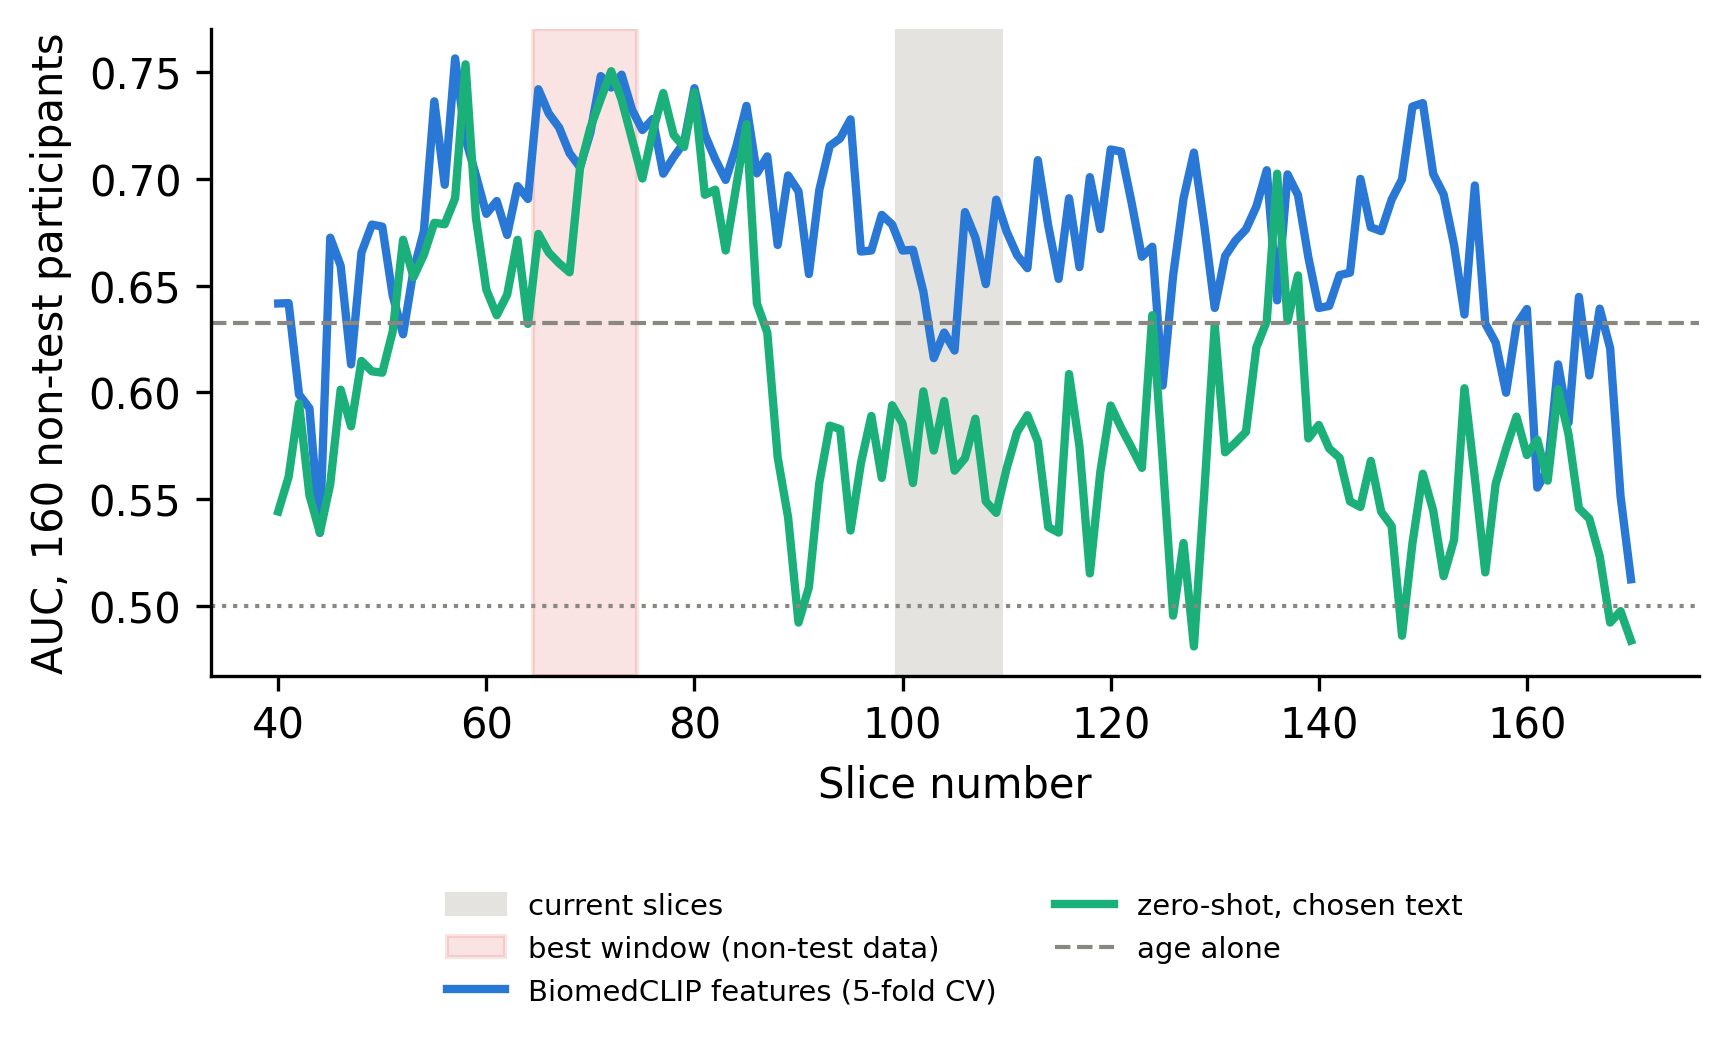

In [ ]:
!python /content/alz_ext/slice_positions.py /content/alz_ext/all_slices_coronal.csv {RESULTS} {MID_FIRST} {MID_FIRST + 9} OASIS1COR 2>&1 | grep -v -i "warn\|pytree\|deprecat"
from IPython.display import Image as Show
Show(f'{RESULTS}/figures/oasis1cor_slice_positions.png', width=650)

In [ ]:
%%writefile /content/alz_ext/select_and_estimate.py
"""Choosing the slices and the text without the test set, and an honest
estimate of how well that works on all 200 participants.

Usage: python select_and_estimate.py ALL_SLICES_CSV RESULTS CURRENT_FIRST [PREFIX FOLDER]
       (PREFIX: saved features of section 15; FOLDER: name of the dataset built from the choice)

Uses the BiomedCLIP features of every slice saved in section 15, so no image
is encoded again and nothing is trained.

Candidates
  slices: windows of 10 consecutive slices, starting every 5 slices
  text:   4 pairs of class names x 4 sets of descriptions (original,
          visible-anatomy, detailed, medial temporal lobe)

1. The choice for section 17: the window and text with the best macro-F1 on
   the 160 non-test participants.
2. The test-set result of that choice (40 people), next to the earlier setup.
3. An honest estimate on all 200 people with 5-fold cross-validation: the
   choice is made on 4 folds (160 people) and scored on the 5th, so every
   person is scored by a choice that never saw them. Three versions show what
   each step adds, and age is checked on the same folds.
All results except the choice itself are per participant (the mean
probability over the person's 10 slices).
"""
import json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

CSV, RESULTS, CUR_FIRST = sys.argv[1], sys.argv[2], int(sys.argv[3])
FEAT_STEM = sys.argv[4] if len(sys.argv) > 4 else 'OASIS1'
FOLDER = sys.argv[5] if len(sys.argv) > 5 else 'OASIS1SEL'
WINDOW, STEP = 10, 5
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, _ = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

df = pd.read_csv(CSV).reset_index(drop=True)
index = pd.read_csv(f'{RESULTS}/{FEAT_STEM}_all_slice_index.csv')
assert (index.subject.values == df.subject.values).all() and (index.slice.values == df.slice.values).all(), \
    'the saved features do not match the slice list: run section 15 first'
feats = np.load(f'{RESULTS}/{FEAT_STEM}_all_slice_features.npy')

NAME_PAIRS = {
    'original': ('no dementia', 'dementia'),
    'healthy_ad': ('healthy aging', "Alzheimer's disease"),
    'normal_atrophy': ('normal brain', 'atrophied brain'),
    'cn_dementia': ('cognitively normal', 'dementia'),
}
DESC_SETS = ['original', 'visible', 'detailed', 'mtl']
OLD = ['no dementia', 'dementia']
DESC = {t: json.load(open(f'/content/alz_ext/descriptions_{t}.json')) for t in DESC_SETS}


@torch.no_grad()
def prototypes(texts_per_class):
    # Same as the authors' zero-shot code: mean of the normalised text features.
    return torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                        for t in texts_per_class]).cpu().numpy()


def p_dementia(W):
    logits = SCALE * feats @ W.T
    logits -= logits.max(1, keepdims=True)
    e = np.exp(logits)
    return e[:, 1] / e.sum(1)


P = {}
for key, names in NAME_PAIRS.items():
    for d in DESC_SETS:
        texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in DESC[d][o]] for o, n in zip(OLD, names)]
        P[(key, d)] = p_dementia(prototypes(texts))
P[('original', 'template')] = p_dementia(prototypes([[f'a photo of a {n}.'] for n in OLD]))
CANDIDATES = [c for c in P if c[1] != 'template']   # BiomedCoOp needs descriptions

STARTS = list(range(int(df.slice.min()), int(df.slice.max()) - WINDOW + 2, STEP))
in_window = {s: ((df.slice >= s) & (df.slice < s + WINDOW)).values for s in STARTS + [CUR_FIRST]}
people = df.drop_duplicates('subject').set_index('subject')[['part', 'y', 'age']]
y_slice = df.y.values


def slice_f1(rows, start, combo):
    m = rows & in_window[start]
    return f1_score(y_slice[m], (P[combo][m] > 0.5).astype(int), average='macro')


def choose(rows, starts, combos):
    return max(((s, c) for s in starts for c in combos), key=lambda sc: slice_f1(rows, *sc))


def person_prob(subjects, start, combo):
    m = df.subject.isin(subjects).values & in_window[start]
    return pd.Series(P[combo][m], index=df.subject.values[m]).groupby(level=0).mean().reindex(subjects)


def ci(y, pred, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    v = [f1_score(y[i], pred[i], average='macro') for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return 100 * np.percentile(v, 2.5), 100 * np.percentile(v, 97.5)


def line(name, y, pred):
    acc, f1 = 100 * (pred == y).mean(), 100 * f1_score(y, pred, average='macro')
    lo, hi = ci(y, pred)
    print(f'  {name:<46} accuracy {acc:5.1f}%  macro-F1 {f1:5.1f}% (95% CI {lo:.1f}-{hi:.1f})')
    return {'result': name, 'n': len(y), 'accuracy': round(acc, 2), 'macro_f1': round(f1, 2),
            'ci_low': round(lo, 2), 'ci_high': round(hi, 2)}


table = []

# 1. The choice for section 17, made on the 160 non-test participants
nontest = people.index[people.part != 'test']
rows_nt = df.subject.isin(nontest).values
start, combo = choose(rows_nt, STARTS, CANDIDATES)
names = NAME_PAIRS[combo[0]]
choice = {'names': list(names), 'desc': combo[1], 'folder': FOLDER, 'first': start, 'last': start + WINDOW - 1}
json.dump(choice, open(f'{RESULTS}/{FOLDER}_choice.json', 'w'), indent=1)
print(f'1. Chosen on the 160 non-test participants: slices {start}-{start + WINDOW - 1}, '
      f'names {names}, {combo[1]} descriptions (macro-F1 per slice there: {100 * slice_f1(rows_nt, start, combo):.1f}%)')

# 2. Test set (40 people), new choice next to the earlier setup
test = people.index[people.part == 'test']
y_test = people.y[test].values
old = json.load(open(f'{RESULTS}/OASIS1BIN_chosen_names.json'))
old_combo = (next(k for k, v in NAME_PAIRS.items() if list(v) == list(old['names'])), old['desc'])
print('\n2. Test set, per participant (40 people)')
for name, (s, c) in [('middle window, one template', (CUR_FIRST, ('original', 'template'))),
                     ('middle window, text chosen in notebook 3', (CUR_FIRST, old_combo)),
                     ('slices and text chosen above', (start, combo))]:
    table.append({'part': 'test (40)', **line(name, y_test, (person_prob(test, s, c).values > 0.5).astype(int))})

# 3. Honest estimate on all 200 people (5-fold cross-validation)
print('\n3. All 200 participants, 5-fold cross-validation (each person scored by a choice made without them)')
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(people.index, people.y))
versions = {'A. middle slices, one template (no choice)': ([CUR_FIRST], [('original', 'template')]),
            'B. middle slices, text chosen': ([CUR_FIRST], CANDIDATES),
            'C. slices and text chosen': (STARTS, CANDIDATES)}
y_all = people.y.values
oof_c, chosen_c = None, []
for name, (starts, combos) in versions.items():
    prob = pd.Series(np.nan, index=people.index)
    for tr, te in folds:
        rows_tr = df.subject.isin(people.index[tr]).values
        s, c = choose(rows_tr, starts, combos)
        prob.iloc[te] = person_prob(people.index[te], s, c).values
        if name.startswith('C'):
            chosen_c.append((s, c))
    table.append({'part': 'all 200 (CV)', **line(name, y_all, (prob.values > 0.5).astype(int))})
    if name.startswith('C'):
        oof_c = prob

age_prob, both_prob = pd.Series(np.nan, index=people.index), pd.Series(np.nan, index=people.index)
for (tr, te), (s, c) in zip(folds, chosen_c):
    lr = LogisticRegression(class_weight='balanced').fit(people[['age']].iloc[tr], y_all[tr])
    age_prob.iloc[te] = lr.predict_proba(people[['age']].iloc[te])[:, 1]
    score_tr = person_prob(people.index[tr], s, c).values
    score_te = person_prob(people.index[te], s, c).values
    X_tr = np.c_[people.age.values[tr], score_tr]
    X_te = np.c_[people.age.values[te], score_te]
    lr2 = LogisticRegression(class_weight='balanced').fit(X_tr, y_all[tr])
    both_prob.iloc[te] = lr2.predict_proba(X_te)[:, 1]
table.append({'part': 'all 200 (CV)', **line('age only', y_all, (age_prob.values > 0.5).astype(int))})
table.append({'part': 'all 200 (CV)', **line('age + version C score', y_all, (both_prob.values > 0.5).astype(int))})
old70 = (people.age >= 70).values
print(f'\n   aged 70 and over ({old70.sum()} people; mean age: no dementia '
      f'{people.age[old70 & (y_all == 0)].mean():.1f}, dementia {people.age[old70 & (y_all == 1)].mean():.1f})')
table.append({'part': 'aged 70+ (CV)', **line('C. slices and text chosen', y_all[old70],
                                               (oof_c.values[old70] > 0.5).astype(int))})
print('\n   choices made in the 5 folds of version C:')
for s, c in chosen_c:
    print(f'     slices {s}-{s + WINDOW - 1}, {NAME_PAIRS[c[0]]}, {c[1]} descriptions')
pd.DataFrame(table).to_csv(f'{RESULTS}/{FOLDER}_estimate.csv', index=False)

Writing /content/alz_ext/select_and_estimate.py


In [ ]:
!python /content/alz_ext/select_and_estimate.py /content/alz_ext/all_slices_coronal.csv {RESULTS} {MID_FIRST} OASIS1COR OASIS1COR 2>&1 | grep -v -i "warn\|pytree\|deprecat"


1. Chosen on the 160 non-test participants: slices 50-59, names ('normal brain', 'atrophied brain'), original descriptions (macro-F1 per slice there: 58.1%)

2. Test set, per participant (40 people)
  middle window, one template                    accuracy  60.0%  macro-F1  37.5% (95% CI 31.0-42.9)
  middle window, text chosen in notebook 3       accuracy  60.0%  macro-F1  37.5% (95% CI 31.0-42.9)
  slices and text chosen above                   accuracy  62.5%  macro-F1  51.6% (95% CI 35.9-66.7)

3. All 200 participants, 5-fold cross-validation (each person scored by a choice made without them)
  A. middle slices, one template (no choice)     accuracy  59.5%  macro-F1  37.3% (95% CI 34.6-39.8)
  B. middle slices, text chosen                  accuracy  46.0%  macro-F1  42.7% (95% CI 36.2-49.5)
  C. slices and text chosen                      accuracy  60.0%  macro-F1  58.0% (95% CI 50.8-64.7)
  age only                                       accuracy  60.0%  macro-F1  59.6% (95% CI 52.9

## 6. Two classes on the chosen coronal slices



In [ ]:
# Dataset with the coronal slices chosen in section 5.
CHOICE = json.load(open(f'{RESULTS}/OASIS1COR_choice.json'))
OCOR = f"OASIS1COR_{CHOICE['first']}-{CHOICE['last']}"     # results folder, named after the slices
cor_dir = f'{DATA}/OASIS1COR'
shutil.rmtree(cor_dir, ignore_errors=True)
chosen = allcor[(allcor.slice >= CHOICE['first']) & (allcor.slice <= CHOICE['last'])]
NAMES = ['no dementia', 'dementia']
split_cor = {'train': [], 'val': [], 'test': []}
for _, r in chosen.iterrows():
    folder = ['no_dementia', 'dementia'][int(r.y)]
    rel = f'{folder}/{r.subject}_{r.slice:03d}.jpg'
    os.makedirs(f'{cor_dir}/images/{folder}', exist_ok=True)
    shutil.copy(r.file, f'{cor_dir}/images/{rel}')
    split_cor[r.part].append((rel, int(r.y), NAMES[int(r.y)]))
json.dump(split_cor, open(f'{cor_dir}/split_OASIS1COR.json', 'w'), indent=1)
keep = f'{OUTPUTS}/{OCOR}_fewshot_samples'
os.makedirs(keep, exist_ok=True)
os.symlink(keep, f'{cor_dir}/split_fewshot')
use_names(CHOICE['names'], CHOICE['desc'], 'OASIS1COR')
print(OCOR, '| names:', CHOICE['names'], '| descriptions:', CHOICE['desc'])
print('images:', {p: len(v) for p, v in split_cor.items()}, '| participants:',
      chosen.groupby('part').subject.nunique().to_dict())

OASIS1COR_50-59 | names: ['normal brain', 'atrophied brain'] | descriptions: original
images: {'train': 1200, 'val': 400, 'test': 400} | participants: {'test': 40, 'train': 120, 'val': 40}


In [ ]:
use_names(CHOICE['names'], CHOICE['desc'], 'OASIS1COR')
run('ZeroshotBiomedCLIP', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/{OCOR}/zeroshot_named',
    eval_only=True, script=WRAPPER['named'])
run('ZeroshotBiomedCLIP2', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/{OCOR}/zeroshot_ensemble_named',
    eval_only=True, script=WRAPPER['named'])

already done: OASIS1COR_50-59/zeroshot_named
already done: OASIS1COR_50-59/zeroshot_ensemble_named


In [ ]:
use_names(CHOICE['names'], CHOICE['desc'], 'OASIS1COR')
for k in SHOTS:
    for seed in SEEDS:
        run('BiomedCoOp_BiomedCLIP', DATASET_CFG['OASIS1BINR'], STRONG_CFG,
            f'{OUTPUTS}/{OCOR}/biomedcoop_named_strong/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=BIOMEDCOOP_OPTS, script=WRAPPER['named'])

already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_1/seed1
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_1/seed2
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_1/seed3
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_2/seed1
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_2/seed2
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_2/seed3
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_4/seed1
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_4/seed2
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_4/seed3
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_8/seed1
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_8/seed2
already done: OASIS1COR_50-59/biomedcoop_named_strong/shots_8/seed3

OASIS1COR_50-59/biomedcoop_named_strong/shots_16/seed1
    * accuracy: 62.25%
    * macro_f1: 53.31%

OASIS1COR_50-59/biomedcoop_named_strong/shots_16/seed2
    * accuracy: 63.50%
   

In [ ]:
!python /content/alz_ext/zs_linear_probe.py {DATA} {OUTPUTS} {RESULTS} OASIS1COR {RESULTS}/OASIS1COR_choice.json {OCOR} 2>&1 | grep -v -i "warn\|pytree\|deprecat\|Reading split"


text prototypes from: {'names': ['normal brain', 'atrophied brain'], 'desc': 'original', 'folder': 'OASIS1COR', 'first': 50, 'last': 59}

zero-shot with the chosen text: validation macro-F1 60.5%, test macro-F1 59.2%
ZS-LP K=1 seed=1, lambda = 100: accuracy 66.5%  macro-F1 60.5%  | per participant: accuracy 65.0%  macro-F1 49.8%
ZS-LP K=1 seed=2, lambda = 10: accuracy 52.5%  macro-F1 52.3%  | per participant: accuracy 42.5%  macro-F1 41.6%
ZS-LP K=1 seed=3, lambda = 1: accuracy 65.2%  macro-F1 61.5%  | per participant: accuracy 72.5%  macro-F1 68.0%
ZS-LP K=2 seed=1, lambda = 100: accuracy 65.2%  macro-F1 62.1%  | per participant: accuracy 70.0%  macro-F1 64.3%
ZS-LP K=2 seed=2, lambda = 100: accuracy 54.8%  macro-F1 54.7%  | per participant: accuracy 55.0%  macro-F1 54.5%
ZS-LP K=2 seed=3, lambda = 100: accuracy 51.0%  macro-F1 50.7%  | per participant: accuracy 45.0%  macro-F1 42.7%
ZS-LP K=4 seed=1, lambda = 100: accuracy 65.5%  macro-F1 56.0%  | per participant: accuracy 67.5%  mac

In [ ]:
use_names(CHOICE['names'], CHOICE['desc'], 'OASIS1COR')
for k in SHOTS:
    for seed in SEEDS:
        run('CoOp_BiomedCLIP', DATASET_CFG['OASIS1BINR'], COOP_CFG,
            f'{OUTPUTS}/{OCOR}/coop_named/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=COOP_OPTS, script=WRAPPER['named'])


OASIS1COR_50-59/coop_named/shots_1/seed1
    * accuracy: 63.00%
    * macro_f1: 46.53%

OASIS1COR_50-59/coop_named/shots_1/seed2
    * accuracy: 46.25%
    * macro_f1: 45.68%

OASIS1COR_50-59/coop_named/shots_1/seed3
    * accuracy: 61.75%
    * macro_f1: 49.83%

OASIS1COR_50-59/coop_named/shots_2/seed1
    * accuracy: 65.50%
    * macro_f1: 63.39%

OASIS1COR_50-59/coop_named/shots_2/seed2
    * accuracy: 37.25%
    * macro_f1: 33.16%

OASIS1COR_50-59/coop_named/shots_2/seed3
    * accuracy: 52.50%
    * macro_f1: 48.46%

OASIS1COR_50-59/coop_named/shots_4/seed1
    * accuracy: 64.75%
    * macro_f1: 56.64%

OASIS1COR_50-59/coop_named/shots_4/seed2
    * accuracy: 56.75%
    * macro_f1: 55.42%

OASIS1COR_50-59/coop_named/shots_4/seed3
    * accuracy: 64.25%
    * macro_f1: 58.84%

OASIS1COR_50-59/coop_named/shots_8/seed1
    * accuracy: 62.00%
    * macro_f1: 52.62%

OASIS1COR_50-59/coop_named/shots_8/seed2
    * accuracy: 60.25%
    * macro_f1: 54.04%

OASIS1COR_50-59/coop_named/shot

## 7. Results: coronal vs axial


In [ ]:
LABELS = {
    'zeroshot_named': 'Zero-shot, one template, chosen names',
    'zeroshot_ensemble_named': 'Zero-shot, chosen names and descriptions',
    'zs_linear_probe': 'Zero-shot-initialised linear probe',
    'coop_named': 'CoOp, chosen names',
    'biomedcoop_named_strong': 'BiomedCoOp, strong text guidance',
}
fmt = lambda m, s: f'{m:.1f}' if np.isnan(s) else f'{m:.1f} ± {s:.1f}'


def acc_table(key):
    runs, summary = collect(key)
    summary = summary[summary.method.isin(LABELS)].copy()
    t = summary.assign(acc=[fmt(m, s) for m, s in zip(summary.accuracy_mean, summary.accuracy_std)])
    t = t.pivot(index='method', columns='shots', values='acc')
    t = t.reindex([m for m in LABELS if m in t.index])
    t.index = [LABELS[m] for m in t.index]
    t.to_csv(f'{RESULTS}/{key}_accuracy_table.csv')
    return summary, t


print('Test-set accuracy (%), 40 people; always predicting the largest class gives 60%.')
print('\nCoronal slices,', OCOR)
summary_cor, t_cor = acc_table(OCOR)
display(t_cor)
print('\nAxial middle slices (notebook 3)')
summary_ax, t_ax = acc_table('OASIS1BIN')
display(t_ax)

Test-set accuracy (%), 40 people; always predicting the largest class gives 60%.

Coronal slices, OASIS1COR_50-59


shots,0,1,2,4,8,16
"Zero-shot, one template, chosen names",62.0,NaN,NaN,NaN,NaN,NaN
"Zero-shot, chosen names and descriptions",63.0,NaN,NaN,NaN,NaN,NaN
Zero-shot-initialised linear probe,NaN,61.4 ± 7.8,57.0 ± 7.4,61.7 ± 3.5,60.8 ± 1.1,61.5 ± 5.1
"CoOp, chosen names",NaN,57.0 ± 9.3,51.8 ± 14.1,61.9 ± 4.5,61.8 ± 1.5,63.2 ± 0.6
"BiomedCoOp, strong text guidance",NaN,61.4 ± 0.8,62.2 ± 2.6,62.8 ± 2.0,62.5 ± 0.5,61.9 ± 1.8



Axial middle slices (notebook 3)


shots,0,1,2,4,8,16
"Zero-shot, one template, chosen names",69.0,NaN,NaN,NaN,NaN,NaN
"Zero-shot, chosen names and descriptions",73.2,NaN,NaN,NaN,NaN,NaN
Zero-shot-initialised linear probe,NaN,54.0 ± 6.1,58.2 ± 16.7,61.2 ± 18.5,72.2 ± 2.2,67.5 ± 6.7
"CoOp, chosen names",NaN,39.7 ± 5.6,48.0 ± 16.9,52.8 ± 15.4,55.2 ± 3.2,52.3 ± 11.3
"BiomedCoOp, strong text guidance",NaN,65.0 ± 7.3,67.9 ± 3.2,69.7 ± 5.9,65.1 ± 4.9,70.6 ± 1.5


In [ ]:
# The honest estimates on all 200 participants (5-fold cross-validation).
est = []
for name, f in [('axial', f'{RESULTS}/OASIS1SEL_estimate.csv'), ('coronal', f'{RESULTS}/OASIS1COR_estimate.csv')]:
    if os.path.exists(f):
        est.append(pd.read_csv(f).assign(slices=name))
est = pd.concat(est)
est.to_csv(f'{RESULTS}/estimates_axial_vs_coronal.csv', index=False)
est.pivot_table(index=['part', 'result'], columns='slices', values=['accuracy', 'macro_f1'], sort=False)

accuracy  \
slices                                                            axial   
part          result                                                      
test (40)     earlier: middle slices, one template                67.50   
              earlier: middle slices, text chosen in section 9    75.00   
              new: slices and text chosen above                   62.50   
              middle window, one template                           NaN   
              middle window, text chosen in notebook 3              NaN   
              slices and text chosen above                          NaN   
all 200 (CV)  A. middle slices, one template (no choice)          54.50   
              B. middle slices, text chosen                       64.50   
              C. slices and text chosen                           63.00   
              age only                                            60.00   
              age + version C score                               63.50   
aged 70+ (CV) C. slices and text chosen                           58.33   

                                                                        \
slices                                                         coronal   
part          result                                                     
test (40)     earlier: middle slices, one template                 NaN   
              earlier: middle slices, text chosen in section 9     NaN   
              new: slices and text chosen above                    NaN   
              middle window, one template                        60.00   
              middle window, text chosen in notebook 3           60.00   
              slices and text chosen above                       62.50   
all 200 (CV)  A. middle slices, one template (no choice)         59.50   
              B. middle slices, text chosen                      46.00   
              C. slices and text chosen                          60.00   
              age only                                           60.00   
              age + version C score                              63.00   
aged 70+ (CV) C. slices and text chosen                          53.79   

                                                               macro_f1  \
slices                                                            axial   
part          result                                                      
test (40)     earlier: middle slices, one template                62.18   
              earlier: middle slices, text chosen in section 9    74.42   
              new: slices and text chosen above                   59.43   
              middle window, one template                           NaN   
              middle window, text chosen in notebook 3              NaN   
              slices and text chosen above                          NaN   
all 200 (CV)  A. middle slices, one template (no choice)          51.06   
              B. middle slices, text chosen                       63.51   
              C. slices and text chosen                           61.76   
              age only                                            59.60   
              age + version C score                               63.35   
aged 70+ (CV) C. slices and text chosen                           58.33   

                                                                        
slices                                                         coronal  
part          result                                                    
test (40)     earlier: middle slices, one template                 NaN  
              earlier: middle slices, text chosen in section 9     NaN  
              new: slices and text chosen above                    NaN  
              middle window, one template                        37.50  
              middle window, text chosen in notebook 3           37.50  
              slices and text chosen above                       51.57  
all 200 (CV)  A. middle slices, one templat

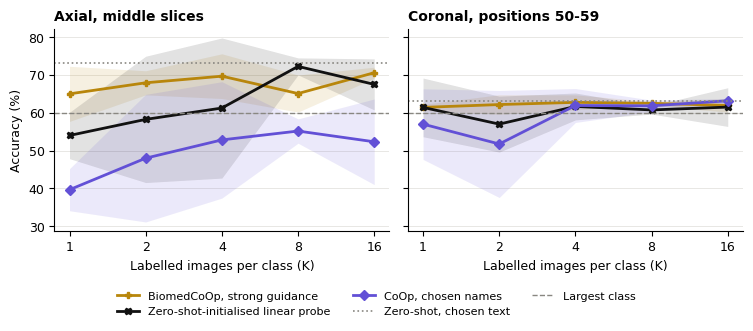

In [ ]:
# Accuracy against K: axial middle slices vs coronal slices.
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'
STYLE = {'biomedcoop_named_strong': ('BiomedCoOp, strong guidance', '#b8860b', 'P'),
         'zs_linear_probe': ('Zero-shot-initialised linear probe', '#111111', 'X'),
         'coop_named': ('CoOp, chosen names', '#6250d6', 'D')}
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9), sharey=True)
for ax, (summary, title) in zip(axes, [(summary_ax, 'Axial, middle slices'), (summary_cor, f'Coronal, positions {OCOR[10:]}')]):
    for method, (label, colour, marker) in STYLE.items():
        d = summary[(summary.method == method) & (summary.shots > 0)]
        if d.empty:
            continue
        mean, std = d.accuracy_mean.values, d.accuracy_std.fillna(0).values
        ax.plot(d.shots, mean, color=colour, marker=marker, markersize=5, linewidth=2, label=label)
        ax.fill_between(d.shots, mean - std, mean + std, color=colour, alpha=0.12, linewidth=0)
    z = summary[summary.method == 'zeroshot_ensemble_named']
    if not z.empty:
        ax.axhline(z.accuracy_mean.iloc[0], color=MUTED, linestyle=':', linewidth=1.2, label='Zero-shot, chosen text')
    ax.axhline(60, color=MUTED, linestyle='--', linewidth=1.0, label='Largest class')
    ax.set_xscale('log', base=2); ax.set_xticks(SHOTS, [str(k) for k in SHOTS])
    ax.grid(axis='y', color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('Labelled images per class (K)'); ax.set_title(title, loc='left', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.14), fontsize=8)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(f'{RESULTS}/figures/axial_vs_coronal.{ext}')
plt.show()